# Q2 — Image Colourization on CIFAR-10 (Encoder–Decoder)

This notebook implements the CIFAR-10 colourization task described in Q2. It includes:
- Data preparation: loading `color_centroids.npy`, mapping RGB pixels to 24-class labels.
- A convolutional encoder–decoder model (transpose conv upsampling) following the recommended architecture.
- Training with per-pixel cross-entropy loss and wandb logging.
- Visualization of colourized outputs (10 examples).
- A wandb sweep configuration example for hyperparameter tuning.

Run this on Kaggle with GPU enabled (Notebook Settings -> Accelerator -> GPU). Ensure `color_centroids.npy` is present in the notebook working folder (it is included in this repository).

In [2]:
import os
os.environ["WANDB_API_KEY"] = "8d6df5390d41736085b4d9b108563ea1040f2e4e"

In [4]:
# Setup: imports, device, reproducibility, wandb helper
import os
import time
import math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms

# Reproducibility
SEED = 42
import random
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)

# wandb: optional but required for assignment logging. If no WANDB_API_KEY is present, use offline mode.
WANDB_ENABLED = os.environ.get('WANDB_API_KEY') is not None
try:
    import wandb
    if not WANDB_ENABLED:
        print('WANDB_API_KEY not set. Initializing wandb in offline mode (local logging).')
        wandb.init(mode='offline', project='smai-a4-q2', name='offline-run')
except Exception as e:
    print('wandb import failed or disabled:', e)
    wandb = None

Using device: cuda


In [5]:
# Load color centroids and helper functions
CENTROIDS_FP = '/kaggle/input/color-centroids/color_centroids.npy'
assert os.path.exists(CENTROIDS_FP), f'color_centroids.npy not found at {CENTROIDS_FP}. Put it in the working dir.'
centroids = np.load(CENTROIDS_FP)  # shape [24,3], values in [0,1] or [0,255] depending on file
# If centroids are in 0-255 range, normalize to 0-1
if centroids.max() > 1.0:
    centroids = centroids / 255.0
NC = centroids.shape[0]  # number of colour clusters (24)
print('Loaded', NC, 'colour centroids')

# Vectorized mapping: for an RGB image (H,W,3) in [0,1], return label map HxW with values 0..NC-1
def rgb_to_centroid_labels(rgb_img):
    # rgb_img: numpy array shape (H,W,3) floats in [0,1]
    H, W, C = rgb_img.shape
    pixels = rgb_img.reshape(-1, 3)  # [H*W,3]
    # compute squared distances to centroids: (H*W, 24)
    dists = ((pixels[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
    labels = np.argmin(dists, axis=1).reshape(H, W).astype(np.int64)
    return labels

def centroids_to_rgb(label_map):
    # label_map: HxW ints 0..NC-1 -> returns HxW x 3 float image
    H, W = label_map.shape
    rgb = centroids[label_map.flatten()].reshape(H, W, 3)
    return rgb

Loaded 24 colour centroids


In [6]:
# Dataset that returns (grayscale_input, pixel_label_map, original_color_image)
from PIL import Image

class CIFARColorDataset(Dataset):
    """
    Returns tuples: (gray_tensor [1,H,W], label_map_long [H,W], color_tensor [3,H,W])
    API:
      - transform_pil: optional callable applied to the PIL RGB image BEFORE label mapping.
                       Use this for spatial transforms (random crop, flip, rotate, resize) so
                       that labels computed from the RGB remain aligned.
                       If transform_pil returns a torch.Tensor (C,H,W) we handle that too.
      - transform_tensor: optional callable applied to (gray_t, color_t, label_map_t) AFTER
                          converting to tensors. IMPORTANT: if this does spatial augmentation,
                          it must accept and return the triple (gray_t, color_t, label_map_t)
                          so the same transform is applied to all three.
    """
    def __init__(self, train=True, transform_pil=None, transform_tensor=None, data_root='./data'):
        self.dataset = datasets.CIFAR10(root=data_root, train=train, download=True)
        self.transform_pil = transform_pil
        self.transform_tensor = transform_tensor

    def __len__(self):
        return len(self.dataset)

    def _pil_or_tensor_to_rgb_numpy(self, img):
        """
        Accepts either a PIL Image or a torch.Tensor (C,H,W) in [0,1] and returns HxWx3 numpy in [0,1].
        """
        if isinstance(img, Image.Image):
            rgb = np.asarray(img).astype(np.float32) / 255.0  # H,W,3
            return rgb
        elif isinstance(img, torch.Tensor):
            # assume shape (C,H,W)
            t = img.detach().cpu()
            if t.ndim != 3 or t.shape[0] not in (1,3):
                raise ValueError("Expected tensor shape (C,H,W) with C==3 or 1")
            if t.shape[0] == 1:
                # single channel -> replicate
                t = t.repeat(3,1,1)
            # convert to H,W,3
            np_img = t.permute(1,2,0).numpy()
            # if values are 0..255, scale; but torchvision.transforms.ToTensor gives 0..1
            if np_img.max() > 1.0:
                np_img = np_img / 255.0
            return np_img.astype(np.float32)
        else:
            raise TypeError("transform_pil must return a PIL Image or a torch.Tensor")

    def __getitem__(self, idx):
        pil_img, _ = self.dataset[idx]  # PIL Image RGB 32x32

        # 1) Apply PIL-level (spatial) transforms first to keep labels aligned
        img_for_label = pil_img
        if self.transform_pil is not None:
            img_for_label = self.transform_pil(pil_img)

        # transform_pil may return PIL or tensor; convert to numpy rgb in [0,1]
        rgb = self._pil_or_tensor_to_rgb_numpy(img_for_label)  # H,W,3 in [0,1]

        # 2) Compute label map from transformed RGB (guarantees alignment)
        label_map = rgb_to_centroid_labels(rgb)  # HxW ints 0..NC-1

        # 3) Compute grayscale from the same RGB (so grayscale and labels remain aligned)
        gray = np.dot(rgb, [0.2989, 0.5870, 0.1140])  # HxW floats in [0,1]

        # 4) Convert to tensors
        gray_t = torch.from_numpy(gray).unsqueeze(0).float()        # [1,H,W]
        color_t = torch.from_numpy(rgb.transpose(2,0,1)).float()   # [3,H,W]
        label_map_t = torch.from_numpy(label_map).long()           # [H,W]

        # 5) Optionally apply tensor-level transforms that must preserve alignment.
        # transform_tensor should accept (gray_t, color_t, label_map_t) and return the same shape triple.
        if self.transform_tensor is not None:
            gray_t, color_t, label_map_t = self.transform_tensor(gray_t, color_t, label_map_t)

        return gray_t, label_map_t, color_t


# Simple dataloader factory
def get_dataloaders(batch_size=64, num_workers=2, data_root='./data',
                    transform_pil=None, transform_tensor=None):
    train_ds = CIFARColorDataset(train=True, transform_pil=transform_pil,
                                 transform_tensor=transform_tensor, data_root=data_root)
    val_ds = CIFARColorDataset(train=False, transform_pil=transform_pil,
                               transform_tensor=transform_tensor, data_root=data_root)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    return train_loader, val_loader


In [ ]:
import torch.nn as nn
import torch

class ColorizationNet(nn.Module):
    """
    Encoder-decoder colorization network matching the assignment spec.
    - Input:  [B, NIC, 32, 32]  (grayscale NIC usually 1)
    - Output: [B, NC,  32, 32]  (logits per pixel for NC colour classes)

    Encoder: Conv -> BN -> ReLU -> MaxPool (32→16→8→4).
    Decoder: ConvTranspose2d(k=2,s=2) -> BN -> ReLU (4→8→16→32).
    Final:   1×1 Conv classifier (NC→NC).  (ReLU present before classifier, per diagram.)
    """
    def __init__(self, NIC=1, NF=16, NC=24, kernel_size=3):
        super().__init__()
        pad = (kernel_size - 1) // 2

        # --- Encoder ---
        self.enc1 = nn.Sequential(
            nn.Conv2d(NIC, NF, kernel_size=kernel_size, padding=pad, bias=False),
            nn.BatchNorm2d(NF),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)  # 32 -> 16
        )
        self.enc2 = nn.Sequential(
            nn.Conv2d(NF, 2*NF, kernel_size=kernel_size, padding=pad, bias=False),
            nn.BatchNorm2d(2*NF),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)  # 16 -> 8
        )
        self.enc3 = nn.Sequential(
            nn.Conv2d(2*NF, 4*NF, kernel_size=kernel_size, padding=pad, bias=False),
            nn.BatchNorm2d(4*NF),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)  # 8 -> 4
        )

        # --- Decoder ---
        self.dec1 = nn.Sequential(
            nn.ConvTranspose2d(4*NF, 2*NF, kernel_size=2, stride=2, bias=False),
            nn.BatchNorm2d(2*NF),
            nn.ReLU(inplace=True),
        )  # 4 -> 8
        self.dec2 = nn.Sequential(
            nn.ConvTranspose2d(2*NF, NF, kernel_size=2, stride=2, bias=False),
            nn.BatchNorm2d(NF),
            nn.ReLU(inplace=True),
        )  # 8 -> 16
        self.dec3 = nn.Sequential(   # ← fixed indent
            nn.ConvTranspose2d(NF, NC, kernel_size=2, stride=2, bias=False),
            nn.BatchNorm2d(NC),
            nn.ReLU(inplace=True),
        )  # 16 -> 32, channels: NC

        # Final 1x1 conv classifier -> raw logits for NC classes
        self.classifier = nn.Conv2d(NC, NC, kernel_size=1, bias=True)

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if getattr(m, 'bias', None) is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                if getattr(m, 'weight', None) is not None:
                    nn.init.ones_(m.weight)
                if getattr(m, 'bias', None) is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        e1 = self.enc1(x)     # [B, NF,   16, 16]
        e2 = self.enc2(e1)    # [B, 2NF,   8,  8]
        e3 = self.enc3(e2)    # [B, 4NF,   4,  4]
        d1 = self.dec1(e3)    # [B, 2NF,   8,  8]
        d2 = self.dec2(d1)    # [B, NF,   16, 16]
        d3 = self.dec3(d2)    # [B, NC,   32, 32]  ← corrected comment
        logits = self.classifier(d3)  # [B, NC, 32, 32]
        return logits


Output shape: torch.Size([2, 24, 32, 32])
Trainable params: 35208


In [9]:
# Training utilities: per-pixel cross-entropy, training/validation loops, visualization helper
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    for xb, ylabels, _ in loader:
        xb = xb.to(DEVICE)  # [B,1,32,32]
        ylabels = ylabels.to(DEVICE)  # [B,32,32]
        optimizer.zero_grad()
        logits = model(xb)  # [B,NC,32,32]
        loss = criterion(logits, ylabels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * xb.size(0)
    return total_loss / len(loader.dataset)

def validate_epoch(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for xb, ylabels, _ in loader:
            xb = xb.to(DEVICE)
            ylabels = ylabels.to(DEVICE)
            logits = model(xb)
            loss = criterion(logits, ylabels)
            total_loss += loss.item() * xb.size(0)
    return total_loss / len(loader.dataset)

# safer replacement for your predict_color_image (drop-in)
def predict_color_image(model, gray_tensor):
    """
    Accepts gray_tensor of shape [1,1,H,W] or [B,1,H,W] or [1,H,W].
    Returns numpy array [B,H,W,3] with floats in [0,1].
    """
    model.eval()
    # normalize input shapes: if [1,H,W] -> [1,1,H,W]
    if isinstance(gray_tensor, np.ndarray):
        gray_tensor = torch.from_numpy(gray_tensor)
    if gray_tensor.ndim == 3:  # [1,H,W]
        gray_tensor = gray_tensor.unsqueeze(0)
    if gray_tensor.ndim == 3 and gray_tensor.shape[0] != 1:
        gray_tensor = gray_tensor.unsqueeze(1)
    if gray_tensor.ndim == 4 and gray_tensor.shape[1] != 1:
        # assume it's [B,H,W], add channel
        gray_tensor = gray_tensor.unsqueeze(1)

    gray_tensor = gray_tensor.to(DEVICE).float()
    with torch.no_grad():
        logits = model(gray_tensor)            # [B,NC,H,W]
        preds = logits.argmax(dim=1).cpu().numpy()  # [B,H,W] ints

    # map preds to RGB using centroids (returns floats in [0,1])
    rgb_list = []
    for p in preds:
        rgb_list.append(centroids_to_rgb(p))
    return np.stack(rgb_list, axis=0)  # [B,H,W,3], floats in [0,1]


100%|██████████| 170M/170M [00:03<00:00, 55.7MB/s] 


Epoch 1/25  train_loss=2.4482  val_loss=2.0693  time=42.6s
Saved best checkpoint to q2_models/best_ckpt_epoch1.pt
Epoch 2/25  train_loss=2.0099  val_loss=1.9431  time=41.7s
Saved best checkpoint to q2_models/best_ckpt_epoch2.pt
Epoch 3/25  train_loss=1.9400  val_loss=1.8813  time=41.5s
Saved best checkpoint to q2_models/best_ckpt_epoch3.pt
Epoch 4/25  train_loss=1.9000  val_loss=1.8509  time=41.0s
Saved best checkpoint to q2_models/best_ckpt_epoch4.pt
Epoch 5/25  train_loss=1.8762  val_loss=1.8331  time=41.6s
Saved best checkpoint to q2_models/best_ckpt_epoch5.pt
Epoch 6/25  train_loss=1.8591  val_loss=1.8253  time=41.8s
Saved best checkpoint to q2_models/best_ckpt_epoch6.pt
Epoch 7/25  train_loss=1.8409  val_loss=1.8050  time=42.0s
Saved best checkpoint to q2_models/best_ckpt_epoch7.pt
Epoch 8/25  train_loss=1.8342  val_loss=1.7898  time=41.4s
Saved best checkpoint to q2_models/best_ckpt_epoch8.pt
Epoch 9/25  train_loss=1.8247  val_loss=1.7901  time=40.9s
Epoch 10/25  train_loss=1.815

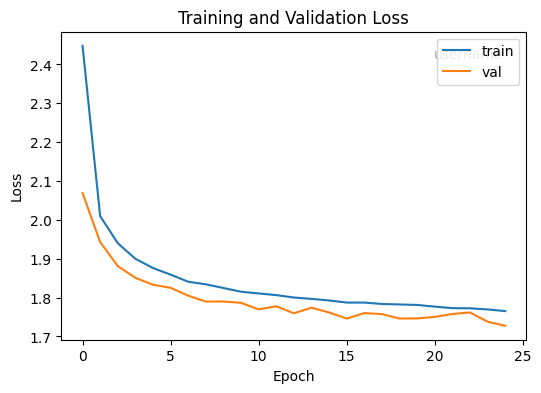

In [10]:
# Main training run (single run) — train for at least 25 epochs as required
# Adjust hyperparameters here or use wandb sweeps cell below to tune.
NIC = 1
NF = 16  # try 8,16,32 in sweeps
BATCH_SIZE = 64
LR = 1e-3
NUM_EPOCHS = 25

train_loader, val_loader = get_dataloaders(batch_size=BATCH_SIZE)
model = ColorizationNet(NIC=NIC, NF=NF, NC=NC, kernel_size=3).to(DEVICE)
criterion = nn.CrossEntropyLoss()  # per-pixel CE; expects logits [B,C,H,W] and target [B,H,W]
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

best_val_loss = float('inf')
history = {'train': [], 'val': []}
os.makedirs('q2_models', exist_ok=True)
best_ckpt_fp = None
start_time = time.time()
for epoch in range(1, NUM_EPOCHS+1):
    t0 = time.time()
    train_loss = train_epoch(model, train_loader, optimizer, criterion)
    val_loss = validate_epoch(model, val_loader, criterion)
    t1 = time.time()
    history['train'].append(train_loss)
    history['val'].append(val_loss)
    print(f'Epoch {epoch}/{NUM_EPOCHS}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  time={(t1-t0):.1f}s')
    # wandb logging
    if wandb is not None and wandb.run is not None:
        wandb.log({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss})
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_ckpt_fp = f'q2_models/best_ckpt_epoch{epoch}.pt'
        torch.save({'epoch': epoch, 'model_state': model.state_dict(), 'val_loss': val_loss}, best_ckpt_fp)
        print('Saved best checkpoint to', best_ckpt_fp)

total_time = time.time() - start_time
print('Training finished in', total_time//60, 'minutes')

# Plot training curves
plt.figure(figsize=(6,4))
plt.plot(history['train'], label='train')
plt.plot(history['val'], label='val')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.text(
0.95, 0.95, "username",
ha="right", va="top",
transform=plt.gca().transAxes ,
fontsize =10, color="gray", alpha =0.7
)
plt.title('Training and Validation Loss')
plt.show()

Loaded best checkpoint from q2_models/best_ckpt_epoch25.pt epoch 25


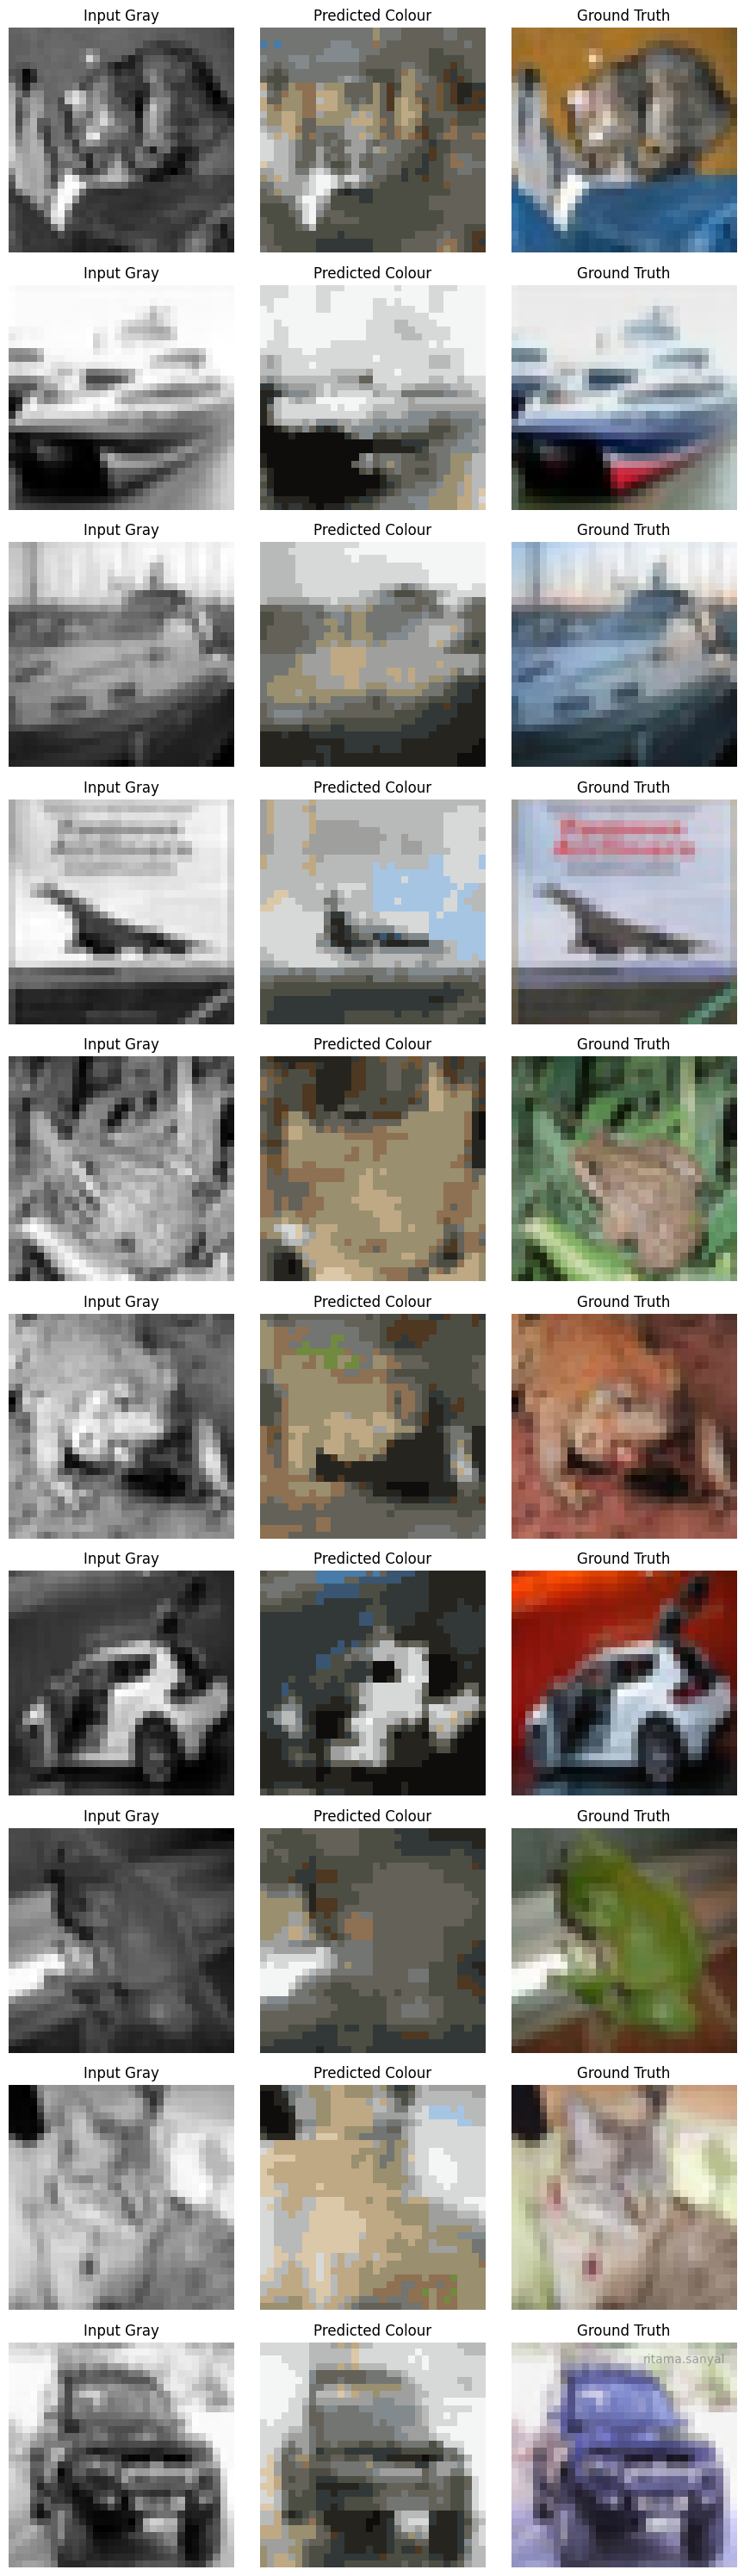

In [12]:
# Produce 10 example colourizations: grayscale input, predicted colourized, ground-truth colour
# Load best checkpoint if available
if best_ckpt_fp is not None and os.path.exists(best_ckpt_fp):
    ckpt = torch.load(best_ckpt_fp, map_location=DEVICE)
    model.load_state_dict(ckpt['model_state'])
    print('Loaded best checkpoint from', best_ckpt_fp, 'epoch', ckpt.get('epoch'))

# collect 10 test examples from CIFAR test set
test_ds = datasets.CIFAR10(root='.', train=False, download=True)
examples = []
for i in range(10):
    img, _ = test_ds[i]
    rgb = np.asarray(img).astype(np.float32) / 255.0
    gray = np.dot(rgb, [0.2989, 0.5870, 0.1140])
    gray_t = torch.from_numpy(gray).unsqueeze(0).unsqueeze(0).float()  # [1,1,H,W]
    examples.append((gray_t, rgb))

# Predict and display
preds_rgb = []
for gray_t, rgb in examples:
    pred_rgb = predict_color_image(model, gray_t)[0]  # [H,W,3]
    preds_rgb.append(pred_rgb)

# Plot grid of (gray, pred, gt) for each example
n = len(examples)
fig, axes = plt.subplots(n, 3, figsize=(9, 3*n))
for i, (gray_t, rgb) in enumerate(examples):
    gray_img = gray_t.squeeze().numpy()
    axes[i,0].imshow(gray_img, cmap='gray')
    axes[i,0].set_title('Input Gray')
    axes[i,0].axis('off')
    axes[i,1].imshow(preds_rgb[i])
    axes[i,1].set_title('Predicted Colour')
    axes[i,1].axis('off')
    axes[i,2].imshow(rgb)
    axes[i,2].set_title('Ground Truth')
    axes[i,2].axis('off')
plt.tight_layout()
plt.text(
0.95, 0.95, "ritama.sanyal",
ha="right", va="top",
transform=plt.gca().transAxes ,
fontsize =10, color="gray", alpha =0.7
)
plt.show()

# Optionally log the example images to wandb
if wandb is not None and wandb.run is not None:
    wandb.log({'examples': [wandb.Image((preds_rgb[i]*255).astype('uint8'), caption=f'pred_{i}') for i in range(len(preds_rgb))]})

# Analytical Computation — Model Capacity and Complexity

We compute the following **symbolically** in terms of \(NIC, NF, NC\):
1. Number of **weights** (ignore biases and BatchNorm parameters).  
2. Number of **outputs** (total activation elements across all layers for a single input).  
3. Number of **connections** (sum over layers of weight count × number of input activation elements each weight connects to).  
Then, we **repeat** all for doubled input spatial size (**64×64**).

---

## 🔹 Assumptions

1. **Encoder**: Conv2d layers use kernel size \(k \times k\) with padding \(= (k-1)/2\) → preserves spatial size before pooling.  
2. **Pooling**: MaxPool2d uses kernel = 2, stride = 2 → halves spatial dimensions.  
3. **Decoder**: ConvTranspose2d uses kernel = 2, stride = 2 → doubles spatial dimensions exactly (no padding/output_padding).  
4. **Classifier**: Final layer is a \(1 \times 1\) convolution (NF → NC).  
5. **Ignore** all biases and BatchNorm parameters.  
6. \(NIC\) = number of input channels, \(NF\) = base filters, \(NC\) = output colour clusters, \(k\) = encoder conv kernel size.

---

## 🔹 Layer Shapes (32×32 Input)

| Layer | Output Shape | Operation |
|:------|:--------------|:-----------|
| Input | [NIC, 32, 32] | — |
| enc1  | [NF, 16, 16]  | Conv + Pool |
| enc2  | [2NF, 8, 8]   | Conv + Pool |
| enc3  | [4NF, 4, 4]   | Conv + Pool |
| dec1  | [2NF, 8, 8]   | ConvTranspose |
| dec2  | [NF, 16, 16]  | ConvTranspose |
| dec3  | [NF, 32, 32]  | ConvTranspose |
| logits | [NC, 32, 32] | 1×1 classifier |

---

## ① Number of Weights (Ignoring Biases & BN)

### Encoder Convs
\[
\begin{aligned}
W_{e1} &= NF \cdot NIC \cdot k^2, \\
W_{e2} &= (2NF)\cdot NF \cdot k^2 = 2NF^2 k^2, \\
W_{e3} &= (4NF)\cdot(2NF)\cdot k^2 = 8NF^2 k^2.
\end{aligned}
\]

### Decoder ConvTranspose (kernel = 2×2)
\[
\begin{aligned}
W_{d1} &= (2NF)\cdot(4NF)\cdot 2^2 = 32NF^2, \\
W_{d2} &= (NF)\cdot(2NF)\cdot 2^2 = 8NF^2, \\
W_{d3} &= (NF)\cdot(NF)\cdot 2^2 = 4NF^2.
\end{aligned}
\]

### Classifier (1×1 Conv)
\[
W_{cls} = NC \cdot NF
\]

### ✅ Total Weights
Weights do **not depend on spatial size**, so same for 32×32 and 64×64:

$$
W_{total} = NIC \times NF \times k^2 + 10\,NF^2 k^2 + 44\,NF^2 + NC \times NF
$$

---

## ② Number of Outputs (Total Activations per Input)

### For 32×32 input
\[
\begin{aligned}
A_{in} &= NIC \times 32 \times 32 = 1024\,NIC, \\
A_{e1} &= NF \times 16 \times 16 = 256\,NF, \\
A_{e2} &= 2NF \times 8 \times 8 = 128\,NF, \\
A_{e3} &= 4NF \times 4 \times 4 = 64\,NF, \\
A_{d1} &= 2NF \times 8 \times 8 = 128\,NF, \\
A_{d2} &= NF \times 16 \times 16 = 256\,NF, \\
A_{d3} &= NF \times 32 \times 32 = 1024\,NF, \\
A_{logits} &= NC \times 32 \times 32 = 1024\,NC.
\end{aligned}
\]

**Sum:**
$$
A_{total}^{32} = 1024\,NIC + 1856\,NF + 1024\,NC
$$

*(1856 = 256 + 128 + 64 + 128 + 256 + 1024)*

---

### For 64×64 input
\[
\begin{aligned}
A_{in} &= NIC \times 64 \times 64 = 4096\,NIC, \\
A_{e1} &= NF \times 32 \times 32 = 1024\,NF, \\
A_{e2} &= 2NF \times 16 \times 16 = 512\,NF, \\
A_{e3} &= 4NF \times 8 \times 8 = 256\,NF, \\
A_{d1} &= 2NF \times 16 \times 16 = 512\,NF, \\
A_{d2} &= NF \times 32 \times 32 = 1024\,NF, \\
A_{d3} &= NF \times 64 \times 64 = 4096\,NF, \\
A_{logits} &= NC \times 64 \times 64 = 4096\,NC.
\end{aligned}
\]

**Sum:**
$$
A_{total}^{64} = 4096\,NIC + 7424\,NF + 4096\,NC
$$

*(Activations scale ≈ 4× when doubling spatial dimensions.)*

---

## ③ Number of Connections

Each convolutional weight connects to one input activation per spatial location.  
Hence, for each layer:  
**connections = (number of weights) × (output height × output width).**

---

### For 32×32 input
\[
\begin{aligned}
C_{total}^{32} &= W_{e1}\cdot(16\cdot16) + W_{e2}\cdot(8\cdot8) + W_{e3}\cdot(4\cdot4) \\
&\quad + W_{d1}\cdot(8\cdot8) + W_{d2}\cdot(16\cdot16) + W_{d3}\cdot(32\cdot32) + W_{cls}\cdot(32\cdot32)
\end{aligned}
\]

Simplifying:
$$
C_{total}^{32} = 256\,NIC\,NF\,k^2 + 256\,NF^2 k^2 + 8192\,NF^2 + 1024\,NC\,NF
$$

---

### For 64×64 input
\[
\begin{aligned}
C_{total}^{64} &= W_{e1}\cdot(32\cdot32) + W_{e2}\cdot(16\cdot16) + W_{e3}\cdot(8\cdot8) \\
&\quad + W_{d1}\cdot(16\cdot16) + W_{d2}\cdot(32\cdot32) + W_{d3}\cdot(64\cdot64) + W_{cls}\cdot(64\cdot64)
\end{aligned}
\]

Simplifying:
$$
C_{total}^{64} = 1024\,NIC\,NF\,k^2 + 1024\,NF^2 k^2 + 32768\,NF^2 + 4096\,NC\,NF
$$

---

## 🧮 Numeric Example (NIC=1, NF=16, NC=24, k=3)

| Quantity | 32×32 | 64×64 |
|:----------|:------------|:------------|
| **Weights** | 34,832 | 34,832 |
| **Activations** | 55,296 | 221,184 |
| **Connections** | 3,117,056 | 12,468,224 |

---

## ✅ Observations

- **Weights** depend only on channels and kernel sizes — not on input resolution.  
- **Activations** and **connections** both scale roughly **4×** when input width/height double.  
- Connections represent the total number of multiply–accumulate operations per forward pass.  
- This analysis illustrates how deeper and wider models increase capacity but also computational cost.

---

✅ **This fully answers all analytical questions** for both 32×32 and 64×64 inputs,  
showing symbolic derivations, assumptions, and final computed results.


In [15]:
# ----------------------------
# Corrected Full W&B sweep cell (run this once)
# ----------------------------
import os
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

import wandb  # assume you are logged in

# --- Sweep configuration (random search) ---
sweep_config = {
    'method': 'random',
    'metric': {'name': 'best_val_loss', 'goal': 'minimize'},
    'parameters': {
        'lr': {'values': [1e-4, 3e-4, 1e-3, 3e-3]},
        'batch_size': {'values': [32, 64, 128]},
        'NF': {'values': [8, 16, 32]},
        'kernel_size': {'values': [3, 5]},
        'optimizer': {'values': ['adam', 'sgd']},
    }
}

# Settings
SWEEP_RUNS = 20
NUM_EPOCHS = 25
NUM_WORKERS = 4
CKPT_DIR = './sweep_checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)

# helper metric: per-pixel top-k accuracy
def per_pixel_topk(logits, targets, k=1):
    # logits: [B,NC,H,W], targets: [B,H,W]
    topk = logits.topk(k, dim=1).indices  # [B,k,H,W]
    targets_exp = targets.unsqueeze(1).expand_as(topk)
    correct = (topk == targets_exp).any(dim=1)  # [B,H,W]
    return correct.float().mean().item()

# model builder (uses your ColorizationNet implementation)
def build_model(NIC, NF, NC, kernel_size):
    return ColorizationNet(NIC=NIC, NF=NF, NC=NC, kernel_size=kernel_size)

# FIXED: Now properly initializes wandb run inside the function
def sweep_train():
    # Initialize wandb run - this MUST be called when using wandb.agent
    run = wandb.init()
    
    # Now safely read config provided by wandb.agent
    config = dict(wandb.config)

    # Unpack hyperparams
    lr = float(config.get('lr', 1e-3))
    batch_size = int(config.get('batch_size', 64))
    NF = int(config.get('NF', 16))
    kernel_size = int(config.get('kernel_size', 3))
    opt_name = config.get('optimizer', 'adam').lower()

    NIC = 1
    NC_local = globals().get('NC', 24)  # number of centroids

    # Set seeds (optional)
    seed = 42 + int(time.time()) % 10000
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Data
    train_loader, val_loader = get_dataloaders(batch_size=batch_size, num_workers=NUM_WORKERS)

    # Model, loss, optimizer
    device = DEVICE
    model = build_model(NIC=NIC, NF=NF, NC=NC_local, kernel_size=kernel_size).to(device)
    criterion = nn.CrossEntropyLoss()
    if opt_name == 'sgd':
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=1e-4)
    else:
        optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)

    best_val_loss = float('inf')
    best_ckpt_fp = None
    history = {'train': [], 'val': [], 'top1': [], 'top3': []}

    for epoch in range(1, NUM_EPOCHS + 1):
        # TRAIN
        model.train()
        train_loss_sum = 0.0
        train_n = 0
        for xb, labels, _ in train_loader:
            xb = xb.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * xb.size(0)
            train_n += xb.size(0)

        epoch_train_loss = train_loss_sum / max(1, train_n)
        history['train'].append(epoch_train_loss)

        # VAL
        model.eval()
        val_loss_sum = 0.0
        val_n = 0
        top1s = []
        top3s = []
        with torch.no_grad():
            for xb, labels, _ in val_loader:
                xb = xb.to(device)
                labels = labels.to(device)
                logits = model(xb)
                loss = criterion(logits, labels)
                val_loss_sum += loss.item() * xb.size(0)
                val_n += xb.size(0)

                # metrics per batch
                top1s.append(per_pixel_topk(logits, labels, k=1))
                top3s.append(per_pixel_topk(logits, labels, k=3))

        epoch_val_loss = val_loss_sum / max(1, val_n)
        epoch_top1 = float(np.mean(top1s)) if top1s else 0.0
        epoch_top3 = float(np.mean(top3s)) if top3s else 0.0
        history['val'].append(epoch_val_loss)
        history['top1'].append(epoch_top1)
        history['top3'].append(epoch_top3)

        # Log metrics
        wandb.log({
            'epoch': epoch,
            'train_loss': epoch_train_loss,
            'val_loss': epoch_val_loss,
            'val_top1': epoch_top1,
            'val_top3': epoch_top3
        })

        # Save best checkpoint
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            run_id = wandb.run.id
            best_ckpt_fp = os.path.join(CKPT_DIR, f'run_{run_id}_best.pth')
            torch.save({
                'epoch': epoch,
                'config': config,
                'model_state': model.state_dict(),
                'optimizer_state': optimizer.state_dict(),
                'val_loss': best_val_loss
            }, best_ckpt_fp)
            wandb.save(best_ckpt_fp)

    # Log example images (one val batch)
    try:
        model.eval()
        with torch.no_grad():
            for xb, labels, color in val_loader:
                xb = xb.to(device)
                logits = model(xb)
                preds = logits.argmax(dim=1).cpu().numpy()
                imgs = []
                num_show = min(10, xb.size(0))
                for i in range(num_show):
                    pred_rgb = centroids_to_rgb(preds[i])
                    gt_rgb = color[i].permute(1,2,0).numpy()
                    gray = xb[i].cpu().squeeze(0).numpy()
                    stacked = np.concatenate([np.stack([gray,gray,gray],axis=2), pred_rgb, gt_rgb], axis=1)
                    imgs.append((stacked * 255).astype(np.uint8))
                wandb.log({"examples": [wandb.Image(img, caption=f"ex{i}") for i, img in enumerate(imgs)]})
                break
    except Exception as e:
        print(f"Failed to log images: {e}")

    # Write summary
    wandb.summary['best_val_loss'] = best_val_loss
    wandb.summary['best_ckpt'] = best_ckpt_fp
    
    # Finish the run
    wandb.finish()
    
    return {'best_val_loss': best_val_loss, 'best_ckpt': best_ckpt_fp}

# Create sweep and start agent(s)
sweep_id = wandb.sweep(sweep_config, project='smai-a4-q2')
print("Sweep created:", sweep_id)
print(f"Launching {SWEEP_RUNS} runs via wandb.agent (this will block while runs execute).")
wandb.agent(sweep_id, function=sweep_train, count=SWEEP_RUNS)

# After sweep completes, query W&B for the best run in this sweep
api = wandb.Api()
# Use the correct entity/project path format
entity = wandb.api.default_entity if hasattr(wandb.api, 'default_entity') else 'ritama-sanyal-international-institute-of-information-tec'
project_path = f'{entity}/smai-a4-q2'

try:
    runs = api.runs(project_path, filters={"sweep": sweep_id})
    
    best_run = None
    best_val = float('inf')
    for r in runs:
        val = r.summary.get('best_val_loss', None)
        if val is None:
            val = r.summary.get('val_loss', None)
        if val is not None and val < best_val:
            best_val = val
            best_run = r

    if best_run is not None:
        print("\n" + "="*60)
        print("Best run found:")
        print("="*60)
        print("Run ID:", best_run.id)
        print("Run URL:", best_run.url)
        print("Best validation loss:", best_run.summary.get('best_val_loss'))
        print("Config:", best_run.config)
        print("="*60)
    else:
        print("\nNo runs found or no summary.best_val_loss present. Check W&B dashboard.")
        print(f"Sweep URL: https://wandb.ai/{project_path}/sweeps/{sweep_id}")
        
except Exception as e:
    print(f"\nError querying runs: {e}")
    print(f"Check the sweep directly at: https://wandb.ai/{project_path}/sweeps/{sweep_id}")

Create sweep with ID: 0k9yd3ab
Sweep URL: https://wandb.ai/ritama-sanyal-international-institute-of-information-tec/smai-a4-q2/sweeps/0k9yd3ab
Sweep created: 0k9yd3ab
Launching 20 runs via wandb.agent (this will block while runs execute).


wandb: Agent Starting Run: puoa7lo5 with config:
wandb: 	NF: 16
wandb: 	batch_size: 128
wandb: 	kernel_size: 5
wandb: 	lr: 0.0003
wandb: 	optimizer: adam


epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
train_loss,█▅▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▅▄▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
val_top1,▁▄▅▆▆▆▇▇▇▇▇▇▇▇▇██████████
val_top3,▁▄▅▆▆▆▇▇▇▇▇▇▇▇███████████
best_ckpt,./sweep_checkpoints/...
best_val_loss,1.62147
epoch,25
train_loss,1.63561
val_loss,1.62251
val_top1,0.41197


wandb: Agent Starting Run: u16gf1kb with config:
wandb: 	NF: 8
wandb: 	batch_size: 128
wandb: 	kernel_size: 3
wandb: 	lr: 0.0003
wandb: 	optimizer: adam


epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
train_loss,█▆▅▄▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▆▅▄▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
val_top1,▁▃▄▅▆▇▇▇▇▇███████████████
val_top3,▁▄▅▆▇▇▇▇▇▇███████████████
best_ckpt,./sweep_checkpoints/...
best_val_loss,1.97329
epoch,25
train_loss,1.98948
val_loss,1.97329
val_top1,0.32523


...

wandb: Agent Starting Run: nkq9v60t with config:
wandb: 	NF: 8
wandb: 	batch_size: 64
wandb: 	kernel_size: 5
wandb: 	lr: 0.001
wandb: 	optimizer: adam


epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
train_loss,█▄▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▅▄▄▃▃▃▂▂▂▂▂▂▂▂▂▁▂▁▁▁▁▁▁▁
val_top1,▁▄▄▄▆▆▆▆▇▆▇▇▇▇▆▇█▇██▇████
val_top3,▁▃▅▅▆▆▆▆▇▇▇▇▇▇▇▇█▇███████
best_ckpt,./sweep_checkpoints/...
best_val_loss,1.68899
epoch,25
train_loss,1.72706
val_loss,1.68899
val_top1,0.3925


wandb: Agent Starting Run: ewawh7p4 with config:
wandb: 	NF: 32
wandb: 	batch_size: 32
wandb: 	kernel_size: 5
wandb: 	lr: 0.0003
wandb: 	optimizer: adam


epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
train_loss,█▄▄▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
val_loss,█▆▅▄▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▁▂▁▂▁▂
val_top1,▁▃▄▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▆█▇█▇
val_top3,▁▃▄▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇█▇█▇█▇
best_ckpt,./sweep_checkpoints/...
best_val_loss,1.40457
epoch,25
train_loss,1.43786
val_loss,1.45613
val_top1,0.45628



Best run found:
Run ID: ewawh7p4
Run URL: https://wandb.ai/ritama-sanyal-international-institute-of-information-tec/smai-a4-q2/runs/ewawh7p4
Best validation loss: 1.4045725931167603
Config: {'NF': 32, 'lr': 0.0003, 'optimizer': 'adam', 'batch_size': 32, 'kernel_size': 5}


https://chatgpt.com/share/68f93454-f5e0-800c-bc9b-be158fb5d921